In [11]:
%pip -q install numpy pandas scikit-learn joblib

import json, math, os, sys, time, warnings, gc, zipfile
from bisect import bisect_right
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import sklearn
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
DT, MAXSTEPS, EPOCH = 5, 2400, pd.Timestamp("2024-01-01")
HOLIDAYS_MD = np.array([107, 119, 302, 501, 505, 528, 911, 927])

def _seg(name, km, slope, ff, road_type, urban=False, remote=False, conflict=0.003):
    return dict(name=name, km=km, slope=slope, ff=ff, road_type=road_type, urban=urban, remote=remote, conflict=conflict)

CORRIDORS = {
    "COR_A": dict(desc="Addis -> Djibouti", has_border=True, segments=[_seg("addis_exit",25,1.5,35,1,urban=True), _seg("addis_adama",75,1.5,62,0), _seg("adama_awash",110,2.0,55,0), _seg("awash_semera",340,1.0,52,2,remote=True,conflict=0.03), _seg("semera_galafi",120,1.0,50,2,remote=True,conflict=0.03), _seg("djibouti_side",240,1.5,55,0,conflict=0.004)], checkpoints=[(210,"check"),(670,"border")], waypoints=[(0,9.03,38.74),(100,8.54,39.27),(210,8.98,40.17),(550,11.79,41.00),(670,11.75,41.85),(910,11.59,43.15)]),
    "COR_B": dict(desc="Addis -> Hawassa", has_border=False, segments=[_seg("addis_exit",25,1.5,35,1,urban=True), _seg("highway",120,1.5,60,0), _seg("rift_valley",80,1.0,55,0), _seg("hawassa_approach",50,1.0,45,1,urban=True)], checkpoints=[], waypoints=[(0,9.03,38.74),(275,7.06,38.48)]),
    "COR_C": dict(desc="Addis -> North", has_border=False, segments=[_seg("addis_exit",25,1.5,35,1,urban=True), _seg("climb",105,4.0,40,2), _seg("mountain",270,4.5,38,2,conflict=0.02), _seg("northern_plateau",380,3.5,42,2,conflict=0.02)], checkpoints=[(130,"check"),(400,"check")], waypoints=[(0,9.03,38.74),(130,9.68,39.53),(400,11.13,39.63),(780,13.50,39.47)]),
    "COR_D": dict(desc="Addis -> Dire Dawa", has_border=False, segments=[_seg("addis_exit",25,1.5,35,1,urban=True), _seg("addis_adama",75,1.5,62,0), _seg("adama_awash",110,2.0,55,0), _seg("awash_mieso",100,2.5,50,2,conflict=0.01), _seg("mieso_hills",205,3.5,42,2,conflict=0.01)], checkpoints=[(310,"check")], waypoints=[(0,9.03,38.74),(100,8.54,39.27),(210,8.98,40.17),(310,9.24,40.75),(515,9.60,41.86)]),
}

for _c in CORRIDORS.values():
    _c["bounds"] = list(np.cumsum([s["km"] for s in _c["segments"]]))
    _c["total_km"], _c["starts"] = float(_c["bounds"][-1]), [0.0] + _c["bounds"][:-1]
    _c["slope_km"] = np.concatenate([np.full(int(s["km"]), s["slope"]) for s in _c["segments"]])
    _c["border_km"] = next((km for km, kind in _c["checkpoints"] if kind == "border"), None)
    _c["cp_kms"] = [km for km, _ in _c["checkpoints"]]

def open_close(dow, hol): return np.where(hol | (dow < 5), 8.0, np.where(dow >= 5, 8.0, 6.0)), np.where(hol, 14.0, np.where(dow >= 5, 17.0, 21.0))

def border_open_info(ts):
    ts, hour = pd.DatetimeIndex(ts), np.asarray(pd.DatetimeIndex(ts).hour) + np.asarray(pd.DatetimeIndex(ts).minute) / 60.0
    o, c = open_close(ts.dayofweek, np.isin(ts.month * 100 + ts.day, HOLIDAYS_MD))
    is_open = (hour >= o) & (hour < c)
    nxt = ts.normalize() + pd.Timedelta(days=1)
    o2, _ = open_close(nxt.dayofweek, np.isin(nxt.month * 100 + nxt.day, HOLIDAYS_MD))
    mins = np.where(is_open, 0.0, np.where(hour < o, (o - hour) * 60, (24.0 - hour + o2) * 60))
    return is_open.astype(float), mins

WET_MONTHS, RAIN_EXP = {"COR_A": (6,7,8,9), "COR_B": (2,3,4,5,6,7,8,9), "COR_C": (2,3,4,5,6,7,8,9), "COR_D": (3,4,5,6,7,8,9)}, {"COR_A": 0.30, "COR_B": 0.72, "COR_C": 0.78, "COR_D": 0.38}
W_DRY, W_WET = np.cumsum([0.75, 0.17, 0.07, 0.01]), np.cumsum([0.35, 0.30, 0.25, 0.10])
C_RUSH, C_URB, C_RURAL = np.cumsum([0.2, 0.3, 0.3, 0.2]), np.cumsum([0.5, 0.3, 0.15, 0.05]), np.cumsum([0.85, 0.10, 0.04, 0.01])
WF, WH, CF = np.array([1.0, 0.93, 0.80, 0.60]), np.array([1.0, 1.1, 1.5, 2.5]), np.array([1.0, 0.85, 0.65, 0.45])

def make_env(rng, ndays=800):
    env = {"alert": {cid: [np.where(rng.random(ndays) > 0.92, np.where(rng.random(ndays) < s["conflict"]*2, 2, np.where(rng.random(ndays) < s["conflict"]*7, 1, 0)), 0) for s in c["segments"]] for cid, c in CORRIDORS.items()}, "queue": np.zeros(ndays)}
    env["queue"][0] = math.log(25)
    for d in range(1, ndays): env["queue"][d] = math.log(25) + 0.85 * (env["queue"][d - 1] - math.log(25)) + rng.normal(0, 0.35)
    env["queue"] = np.exp(env["queue"]); return env

def simulate_trip(cid, start_dt, rng, env):
    c = CORRIDORS[cid]; bounds, total = c["bounds"], c["total_km"]
    weight, age, dss, drv = float(np.clip(rng.normal(24, 8), 5, 40)), float(np.clip(rng.gamma(4.0, 2.2), 0.5, 30)), float(min(rng.exponential(60), 400)), float(np.clip(rng.normal(1.0, 0.08), 0.8, 1.2))
    cont_lim, day_lim, night_driver = rng.uniform(240, 330), rng.uniform(540, 720), rng.random() < 0.35
    idx = pd.date_range(start_dt, periods=MAXSTEPS, freq="5min")
    hours, dows, days, months = idx.hour + idx.minute/60.0, idx.dayofweek, np.clip((idx.normalize() - EPOCH).days, 0, len(env["queue"])-1), idx.month
    hol = np.isin(idx.month * 100 + idx.day, HOLIDAYS_MD)
    bo, bc = open_close(dows, hol); border_open = (hours >= bo) & (hours < bc)
    R, N = rng.random((MAXSTEPS, 6)), rng.normal(size=(MAXSTEPS, 2))
    cps, cp_ptr, pos, v, wait_left, wait_is_border, cont_drive, day_drive, entered_seg = list(c["checkpoints"]), 0, 0.0, 0.0, 0.0, False, 0.0, 0.0, -1
    P, V, W, C_list, S, ev = [], [], [], [], [], {"departed": 0.0, "border_enter": None, "border_exit": None}
    for t in range(MAXSTEPS):
        seg = min(bisect_right(bounds, pos), len(c["segments"]) - 1); sg = c["segments"][seg]
        w = int(np.searchsorted(W_WET if (months[t] in WET_MONTHS[cid] and R[t, 5] < RAIN_EXP[cid]) else W_DRY, R[t, 1])) if R[t, 0] < 1/18 else (W[-1] if W else 0)
        cong = int(np.searchsorted((C_RUSH if (7<=hours[t]<9 or 17<=hours[t]<19) and dows[t]<5 and not hol[t] else C_URB) if sg["urban"] else C_RURAL, R[t, 3])) if R[t, 2] < 1/6 else (C_list[-1] if C_list else 0)
        P.append(pos); V.append(v); W.append(w); C_list.append(cong); state = 0
        if wait_left <= 0:
            if cont_drive >= cont_lim:
                long_rest = day_drive >= day_lim or (not night_driver and 20 <= hours[t] < 22 and day_drive >= 300)
                wait_left, state, cont_drive, day_drive = max(360.0, rng.normal(480, 60)) if long_rest else rng.uniform(25, 60), 2 if long_rest else 1, 0.0, 0.0 if long_rest else day_drive
                wait_is_border = False
            elif seg != entered_seg and pos > 0:
                entered_seg = seg
                if rng.random() < {0: 0.001, 1: 0.02, 2: 0.15}[env["alert"][cid][seg][days[t]]]: wait_left, state, wait_is_border = float(np.exp(rng.normal(math.log(240), 0.8))), 6, False
            elif v > 0 and R[t, 4] < ((v * DT / 60) / 3500 * math.exp(0.07*(age-8)) * (1+dss/200) * WH[w]):
                major = rng.random() < 0.30
                wait_left, state, wait_is_border = float(np.exp(rng.normal(math.log(300 if major else 35), 0.8 if major else 0.6))), 5, False
        if wait_left > 0:
            wait_left -= DT if not wait_is_border or border_open[t] else 0
            v_new = 0.0
            if wait_is_border and wait_left <= 0 and ev["border_exit"] is None: ev["border_exit"] = (t + 1) * DT
        else:
            v_new = float(np.clip(0.6 * (sg["ff"] * drv * (1-min(0.55, sg["slope"]*0.03*(0.4+weight/30))) * WF[w] * CF[cong] * (0.92 if (hours[t]>=22 or hours[t]<5) and not night_driver else 1.0)) + 0.4 * v + 2.5 * N[t, 0], 8, 85))
            pos += v_new * DT / 60; cont_drive += DT; day_drive += DT
            if pos >= total: ev["arrived"] = t * DT + DT * (total - P[-1]) / (pos - P[-1]); break
            if cp_ptr < len(cps) and P[-1] < cps[cp_ptr][0] <= pos:
                pos = float(cps[cp_ptr][0]); cp_ptr += 1
                if cps[cp_ptr-1][1] == "border": wait_left, wait_is_border, ev["border_enter"] = env["queue"][days[t]] * np.where((hours[t]>=6)&(hours[t]<10), 1.3, 0.9) * rng.uniform(2.5, 6.0) + float(np.exp(rng.normal(math.log(60), 0.7))), True, t * DT
                else: wait_left, wait_is_border = float(np.exp(rng.normal(math.log(12), 0.6))), False
        S.append(state if state else (4 if wait_left>0 and wait_is_border else (3 if wait_left>0 else 0))); v = v_new
    if "arrived" not in ev: return None
    return dict(pos=np.array(P), speed=np.array(V), weather=np.array(W), cong=np.array(C_list), state=np.array(S)), dict(corridor=cid, start_dt=start_dt, cargo_weight_tons=weight, truck_age_years=age, days_since_service=dss, total_km=total, arrival_mins=float(ev["arrived"])), ev, dict(hours=hours[:len(P)], days=days[:len(P)], idx=idx[:len(P)])

def observe(truth, static, ctx, env, rng):
    c, T = CORRIDORS[static["corridor"]], len(truth["pos"]); ping = np.ones(T, bool); until = -1
    for t in range(1, T):
        if t <= until: ping[t] = False; continue
        seg = min(bisect_right(c["bounds"], truth["pos"][t]), len(c["segments"]) - 1)
        if rng.random() < (0.012 if c["segments"][seg]["remote"] else 0.0015): until = t + int(math.ceil(float(np.exp(rng.normal(math.log(40), 0.9)))/DT)); ping[t] = False
        elif rng.random() < 0.03: ping[t] = False
    noisy = lambda x, hi: np.clip(np.where(rng.random(T) < 0.15, x + np.where(rng.random(T) < 0.5, -1, 1), x), 0, hi)
    alert = np.array([max([0] + [int(np.clip(env["alert"][static["corridor"]][si][ctx["days"][t]] + int(rng.choice([-1, 0, 1], p=[0.075, 0.85, 0.075])), 0, 2)) for si, (s0, s1) in enumerate(zip(c["starts"], c["bounds"])) if s1 > truth["pos"][t] and s0 < truth["pos"][t] + 200]) for t in range(T)])
    return pd.DataFrame(dict(step=np.arange(T), t_mins=np.arange(T)*DT, ping=ping, pos_obs=np.where(ping, truth["pos"] + rng.normal(0, 0.02, T), np.nan), speed_obs=np.where(ping, np.clip(truth["speed"] + rng.normal(0, 1.0, T), 0, None), np.nan), weather_now=noisy(truth["weather"], 3).astype(float), weather_fcst=np.clip(truth["weather"][np.minimum(np.arange(T) + 24, T - 1)] + rng.normal(0, 0.5, T), 0, 3), cong_obs=noisy(truth["cong"], 3).astype(float), alert_obs=alert, queue_obs=env["queue"][ctx["days"]] * np.where((ctx["hours"]>=6)&(ctx["hours"]<10), 1.3, 0.9) * np.exp(rng.normal(0, 0.25, T)) if c["has_border"] else np.zeros(T)))

In [12]:
FEATURES = ["dr_distance_rem_km", "dist_rem_last_fix_km", "gap_mins", "speed_last_kmh", "time_elapsed_mins", "mean_speed_30m", "speed_std_30m", "stopped_frac_60m", "stop_count_6h", "speed_lag_5m", "speed_lag_10m", "mean_speed_trip", "mins_since_long_stop", "mins_since_long_rest", "hour_sin", "hour_cos", "dow", "month", "is_holiday", "is_night", "seg_slope", "seg_ff_speed", "seg_road_type", "seg_urban", "seg_remote", "slope_next_50km", "km_to_next_checkpoint", "km_to_border", "est_queue_trucks", "border_open_at_baseline_arrival", "mins_until_border_open", "weather_now", "weather_fcst_2h", "congestion_level", "conflict_alert_max_200km", "cargo_weight_tons", "truck_age_years", "days_since_service", "hist_remaining_mins", "baseline_remaining_mins"]

def _wsum(x, W): cs = np.concatenate([[0.0], np.cumsum(x)]); i = np.arange(len(x)); return cs[i + 1] - cs[np.maximum(i + 1 - W, 0)]

def build_features(grid, static, hist):
    c, T, total = CORRIDORS[static["corridor"]], len(grid), static["total_km"]
    steps, ping, pos_obs, spd_obs = np.arange(T), grid["ping"].to_numpy(bool), grid["pos_obs"].to_numpy(float), grid["speed_obs"].to_numpy(float)
    last = np.maximum.accumulate(np.where(ping, steps, -1)); safe = np.where(last >= 0, last, 0)
    gap, pos_fix, spd_fix = (steps - safe) * DT, np.where(last >= 0, pos_obs[safe], 0.0), np.where(last >= 0, spd_obs[safe], 0.0)
    dist_fix = np.clip(total - pos_fix, 0, None); dr = np.clip(dist_fix - spd_fix * gap / 60.0, 0, None); pos_est = total - dr
    m, s, st = ping.astype(float), np.where(ping, spd_obs, 0.0), (ping & (spd_obs < 3)).astype(float)
    cnt30 = _wsum(m, 6); mean30 = np.where(cnt30 > 0, _wsum(s, 6) / np.maximum(cnt30, 1), np.nan)
    std30 = np.sqrt(np.clip(np.where(cnt30 > 0, _wsum(s**2, 6)/np.maximum(cnt30, 1) - np.nan_to_num(mean30)**2, np.nan), 0, None))
    cnt60 = _wsum(m, 12); stopped60 = np.where(cnt60 > 0, _wsum(st, 12) / np.maximum(cnt60, 1), np.nan)
    stopped_ff = spd_fix < 3; ev_start = np.concatenate([[0.0], (stopped_ff[1:] & ~stopped_ff[:-1]).astype(float)]); stop_cnt = _wsum(ev_start, 72)
    lag5, lag10 = np.concatenate([[spd_fix[0]], spd_fix[:-1]]), np.concatenate([[spd_fix[0]] * 2, spd_fix[:-2]])[:T]
    mv = ping & (spd_obs > 5); cn = np.cumsum(mv); mean_trip = np.where(cn > 0, np.cumsum(np.where(mv, spd_obs, 0.0)) / np.maximum(cn, 1), np.nan)
    since_long, since_rest, run, lend, rend = np.zeros(T), np.zeros(T), 0, 0, 0
    for t in range(T):
        run = run + 1 if stopped_ff[t] else 0
        if not stopped_ff[t]: lend, rend = (t if run >= 6 else lend), (t if run >= 60 else rend)
        since_long[t], since_rest[t] = (0 if run >= 6 else (t - lend) * DT), (0 if run >= 60 else (t - rend) * DT)
    ts = pd.DatetimeIndex(static["start_dt"] + pd.to_timedelta(steps * DT, unit="min"))
    hr, mdv, seg = np.asarray(ts.hour) + np.asarray(ts.minute)/60.0, np.asarray(ts.month)*100 + np.asarray(ts.day), np.clip(np.searchsorted(c["bounds"], pos_est, side="right"), 0, len(c["segments"])-1)
    sattr = lambda k: np.array([sg[k] for sg in c["segments"]], float)[seg]
    kmi = np.clip(pos_est.astype(int), 0, len(c["slope_km"])-1); cs_ = np.concatenate([[0], np.cumsum(c["slope_km"])])
    hi = np.clip(kmi + 50, 0, len(c["slope_km"])); slope50 = (cs_[hi] - cs_[kmi]) / np.maximum(hi - kmi, 1)
    cpk = np.array(c["cp_kms"] + [np.inf], float); nxt = np.array([cpk[np.searchsorted(cpk, p, side="right")] for p in pos_est]); km_next = np.where(np.isfinite(nxt), nxt - pos_est, total - pos_est)
    grid_km = np.arange(len(hist[static["corridor"]])); hist_rem = np.clip(np.interp(total, grid_km, hist[static["corridor"]]) - np.interp(pos_est, grid_km, hist[static["corridor"]]), 0, None)
    if c["border_km"] is not None:
        ahead = pos_est < c["border_km"]; km_border, t_arr = np.where(ahead, c["border_km"] - pos_est, np.nan), np.clip(np.interp(c["border_km"], grid_km, hist[static["corridor"]]) - np.interp(pos_est, grid_km, hist[static["corridor"]]), 0, None)
        isopen, mopen = border_open_info(ts + pd.to_timedelta(t_arr, unit="min"))
        isopen, mopen, queue = np.where(ahead, isopen, np.nan), np.where(ahead, mopen, np.nan), np.where(ahead, grid["queue_obs"].to_numpy(float), np.nan)
    else: km_border, isopen, mopen, queue = np.full(T, np.nan), np.full(T, np.nan), np.full(T, np.nan), np.full(T, np.nan)

    return pd.DataFrame({"dr_distance_rem_km": dr, "dist_rem_last_fix_km": dist_fix, "gap_mins": gap.astype(float), "speed_last_kmh": spd_fix, "time_elapsed_mins": steps * float(DT), "mean_speed_30m": mean30, "speed_std_30m": std30, "stopped_frac_60m": stopped60, "stop_count_6h": stop_cnt, "speed_lag_5m": lag5, "speed_lag_10m": lag10, "mean_speed_trip": mean_trip, "mins_since_long_stop": since_long, "mins_since_long_rest": since_rest, "hour_sin": np.sin(2 * np.pi * hr / 24), "hour_cos": np.cos(2 * np.pi * hr / 24), "dow": np.asarray(ts.dayofweek, float), "month": np.asarray(ts.month, float), "is_holiday": np.isin(mdv, HOLIDAYS_MD).astype(float), "is_night": ((hr >= 22) | (hr < 5)).astype(float), "seg_slope": sattr("slope"), "seg_ff_speed": sattr("ff"), "seg_road_type": sattr("road_type"), "seg_urban": sattr("urban"), "seg_remote": sattr("remote"), "slope_next_50km": slope50, "km_to_next_checkpoint": km_next, "km_to_border": km_border, "est_queue_trucks": queue, "border_open_at_baseline_arrival": isopen, "mins_until_border_open": mopen, "weather_now": grid["weather_now"].to_numpy(float), "weather_fcst_2h": grid["weather_fcst"].to_numpy(float), "congestion_level": grid["cong_obs"].to_numpy(float), "conflict_alert_max_200km": grid["alert_obs"].to_numpy(float), "cargo_weight_tons": static["cargo_weight_tons"], "truck_age_years": static["truck_age_years"], "days_since_service": static["days_since_service"], "hist_remaining_mins": hist_rem, "baseline_remaining_mins": np.maximum(hist_rem, 10.0)})[FEATURES]

def time_at_km(truth, static):
    tv, pv = np.append(np.arange(len(truth["pos"])) * float(DT), static["arrival_mins"]), np.append(truth["pos"], static["total_km"])
    kms = np.arange(0, int(static["total_km"]) + 1, dtype=float)
    i = np.clip(np.searchsorted(pv, kms, side="left"), 1, len(pv) - 1)
    out = tv[i - 1] + (tv[i] - tv[i - 1]) * np.clip((kms - pv[i - 1]) / np.maximum(pv[i] - pv[i - 1], 1e-9), 0, 1)
    out[0] = 0.0; return out

def build_hist(archive): return {cid: np.mean([time_at_km(t["truth"], t["static"]) for t in archive if t["static"]["corridor"] == cid], axis=0) for cid in set(t["static"]["corridor"] for t in archive)}, float(np.mean([t["static"]["total_km"] / (t["static"]["arrival_mins"] / 60) for t in archive]))

In [13]:
SEED, TARGET_TRAIN_ROWS, OUT_DIR = 42, 250_000, "/content/eta_artifacts"
os.makedirs(OUT_DIR, exist_ok=True)
rng, env, trips = np.random.default_rng(SEED), make_env(np.random.default_rng(SEED)), []

def add_simulated_trips(counts):
    for cid, n in counts.items():
        for day in np.sort(rng.integers(0, 730, n)):
            u, h = rng.random(), rng.uniform(5, 11) if rng.random() < .60 else (rng.uniform(14, 20) if rng.random() < .85 else rng.uniform(0, 24))
            res = simulate_trip(cid, (EPOCH + pd.Timedelta(days=int(day), hours=float(h))).floor("5min"), rng, env)
            if res: trips.append({"truth": res[0], "static": res[1], "events": res[2], "grid": observe(res[0], res[1], res[3], env, rng), "id": len(trips)})

def rebuild_dataset(all_trips):
    for trip in all_trips: trip.pop("split", None)
    for cid in CORRIDORS:
        route_trips = sorted((t for t in all_trips if t["static"]["corridor"] == cid), key=lambda t: t["static"]["start_dt"])
        for i, trip in enumerate(route_trips):
            f = i / max(len(route_trips), 1)
            trip["split"] = ("archive" if f < .20 else "calib_local" if f < .35 else "unseen") if cid == "COR_D" else ("archive" if f < .20 else "train" if f < .65 else "valid" if f < .75 else "calib" if f < .85 else "test")
    hist_map, mean_speed = build_hist([t for t in all_trips if t["split"] == "archive"])
    frames = []
    for trip in all_trips:
        if trip["split"] == "archive": continue
        f = build_features(trip["grid"], trip["static"], hist_map)
        f["y_rem"], f["trip_id"], f["split"], f["corridor"], f["step"] = trip["static"]["arrival_mins"] - trip["grid"]["t_mins"].to_numpy(), trip["id"], trip["split"], trip["static"]["corridor"], trip["grid"]["step"].to_numpy()
        f["B1"] = f["dr_distance_rem_km"] / mean_speed * 60.0
        frames.append(f[(f["y_rem"] >= 10) & (f["step"] % 2 == 0)])
    data = pd.concat(frames, ignore_index=True)
    data[FEATURES], data["y"] = data[FEATURES].astype("float32"), np.log(data["y_rem"] / data["baseline_remaining_mins"])
    return hist_map, mean_speed, data

print("Simulating trips...")
add_simulated_trips({"COR_A": 1800, "COR_B": 1200, "COR_C": 1200, "COR_D": 1200})
while True:
    hist, vbar, df = rebuild_dataset(trips)
    train_count = int((df["split"] == "train").sum())
    if train_count >= TARGET_TRAIN_ROWS: break
    add_simulated_trips({"COR_A": 300, "COR_B": 200, "COR_C": 200, "COR_D": 200}); gc.collect()

print(f"Data Generation Complete! Total Rows: {len(df):,}")
assert not (set(df.loc[df["split"]=="train", "corridor"]) & {"COR_D"}) and df.groupby("trip_id")["split"].nunique().max() == 1, "Leakage Error!"

Simulating trips...
Data Generation Complete! Total Rows: 765,552


In [14]:
X = lambda d: d[FEATURES].to_numpy(dtype=np.float32)
train, calib, local_cal = df[df["split"] == "train"], df[df["split"] == "calib"], df[df["split"] == "calib_local"]

quantiles, models, t0 = {"q10": .10, "q50": .50, "q90": .90}, {}, time.time()
for name, q in quantiles.items():
    models[name] = HistGradientBoostingRegressor(loss="quantile", quantile=q, max_iter=300, learning_rate=.06, max_leaf_nodes=20, min_samples_leaf=200, l2_regularization=3.0, random_state=SEED).fit(X(train), train["y"].to_numpy())
    print(f"{name} trained in {time.time()-t0:.0f}s")

def predict_log(data):
    lo, med, hi = models["q10"].predict(X(data)), models["q50"].predict(X(data)), models["q90"].predict(X(data))
    return np.minimum(lo, med), med, np.maximum(hi, med)

alpha = .20
lo, _, hi = predict_log(calib)
qhat = float(np.quantile(np.maximum(lo - calib["y"].to_numpy(), calib["y"].to_numpy() - hi), min(1.0, math.ceil((len(calib)+1)*(1-alpha))/len(calib))))
lo_l, _, hi_l = predict_log(local_cal)
qhat_local = float(np.quantile(np.maximum(lo_l - local_cal["y"].to_numpy(), local_cal["y"].to_numpy() - hi_l), min(1.0, math.ceil((len(local_cal)+1)*(1-alpha))/len(local_cal))))

print(f"CQR correction: {qhat:.4f} | Local COR_D correction: {qhat_local:.4f}")

out = Path(OUT_DIR)
joblib.dump({"version": "eta-v1", "sklearn": sklearn.__version__, "features": FEATURES, "models": models, "qhat_log": qhat, "qhat_by_corridor": {"COR_D": qhat_local}, "hist": hist, "vbar": vbar, "dt_minutes": DT}, out/"eta_model_v1.joblib", compress=3)

q10 trained in 31s
q50 trained in 63s
q90 trained in 93s
CQR correction: 0.0366 | Local COR_D correction: 0.2268


['/content/eta_artifacts/eta_model_v1.joblib']

In [15]:
bundle_live = joblib.load(Path(OUT_DIR) / "eta_model_v1.joblib")

def snap_to_route(cid, lat, lon):
    w, best = CORRIDORS[cid]["waypoints"], (0.0, float("inf"))
    for (k0, la0, lo0), (k1, la1, lo1) in zip(w[:-1], w[1:]):
        kx, ky = math.cos(math.radians((la0+la1)/2)) * 111.32, 110.57
        ax, ay, bx, by, px, py = lo0*kx, la0*ky, lo1*kx, la1*ky, lon*kx, lat*ky
        dx, dy = bx-ax, by-ay
        length2 = dx*dx + dy*dy
        u = 0.0 if length2 == 0 else np.clip(((px-ax)*dx + (py-ay)*dy)/length2, 0.0, 1.0)
        off = math.hypot(px-(ax+u*dx), py-(ay+u*dy))
        if off < best[1]: best = (float(k0 + u*(k1-k0)), float(off))
    return best

def validate_live_ping(ping, last_good=None):
    lat, lon, speed = float(ping["lat"]), float(ping["lon"]), float(ping.get("speed_kmh", 0.0))
    if not (3 <= lat <= 16 and 33 <= lon <= 45): return False
    if not (0 <= speed <= 130): return False
    return True

def predict_live_eta(bundle, pings, static):
    cid = static["corridor"]
    grid = pd.DataFrame({"step": np.arange(len(pings)), "t_mins": np.arange(len(pings))*DT, "ping": True, "pos_obs": [snap_to_route(cid, p["lat"], p["lon"])[0] for p in pings], "speed_obs": [p.get("speed_kmh", 0.0) for p in pings], "weather_now": np.nan, "weather_fcst": np.nan, "cong_obs": np.nan, "alert_obs": np.nan, "queue_obs": np.nan})
    features_now = build_features(grid, static, bundle["hist"]).iloc[[-1]]
    xv = features_now[bundle["features"]].to_numpy(dtype=np.float32)
    med = float(bundle["models"]["q50"].predict(xv)[0])
    base = max(float(features_now["baseline_remaining_mins"].iloc[0]), 10.0)
    p50 = max(0.0, base*math.exp(float(np.clip(med, -20, 20))))
    return {"corridor": cid, "distance_remaining_km": round(float(features_now["dr_distance_rem_km"].iloc[0]), 1), "eta_p50_minutes": round(p50, 1)}

# Example Usage
demo_static = {"corridor": "COR_A", "start_dt": pd.Timestamp.now(), "cargo_weight_tons": 24.0, "truck_age_years": 7.0, "days_since_service": 35.0, "total_km": CORRIDORS["COR_A"]["total_km"]}
demo_pings = [{"lat": 9.03, "lon": 38.74, "speed_kmh": 0.0}, {"lat": 8.54, "lon": 39.27, "speed_kmh": 42.0}]
print("Live Prediction:", predict_live_eta(bundle_live, demo_pings, demo_static))

Live Prediction: {'corridor': 'COR_A', 'distance_remaining_km': 810.0, 'eta_p50_minutes': 1965.9}


MODEL PERFORMANCE (ETA errors are in minutes)


,Rows,MAE_min,RMSE_min,R2,Baseline_MAE_min,Improvement_vs_baseline_%,CQR_coverage_%
Split,,,,,,,
train,365323,169.04,267.54,0.89,276.06,38.77,90.78
valid,79237,196.09,286.35,0.87,257.73,23.91,82.33
test,120330,220.08,357.48,0.82,282.08,21.98,80.43
unseen,96505,220.21,304.55,0.54,227.84,3.35,78.03


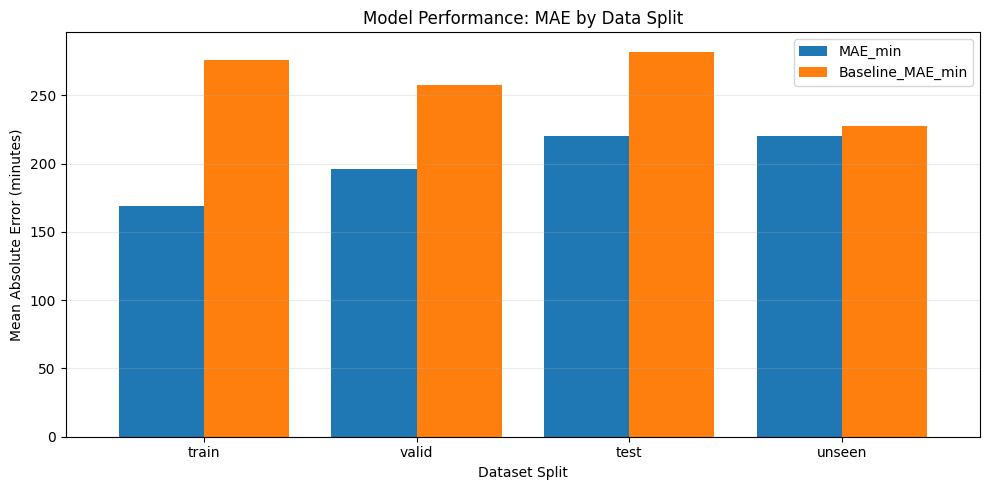

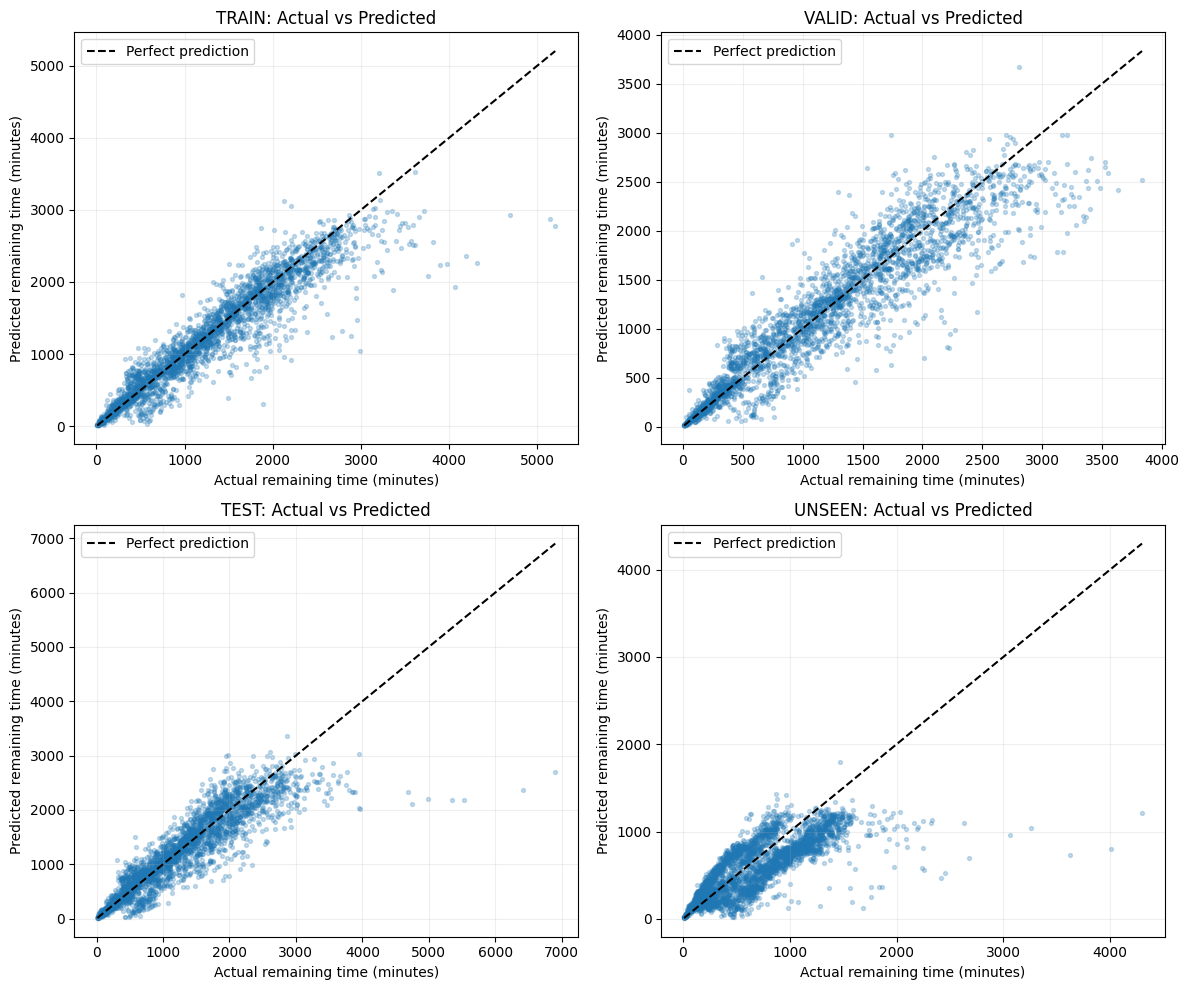

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Performance calculation across all splits
splits = ["train", "valid", "test", "unseen"]
metrics = []
plot_data = {}
rng = np.random.default_rng(SEED)

for split in splits:
    data = df[df["split"] == split]
    if data.empty:
        continue

    lo, med, hi = predict_log(data)
    actual = data["y_rem"].to_numpy(dtype=float)
    baseline = data["baseline_remaining_mins"].to_numpy(dtype=float)

    with np.errstate(over="ignore", invalid="ignore"):
        pred = baseline * np.exp(med)
        correction = qhat_local if split == "unseen" else qhat
        lower = baseline * np.exp(lo - correction)
        upper = baseline * np.exp(hi + correction)

    good = np.isfinite(actual) & np.isfinite(pred) & np.isfinite(baseline)
    if not good.any():
        continue

    y, p, b = actual[good], pred[good], baseline[good]
    mae = mean_absolute_error(y, p)
    rmse = np.sqrt(mean_squared_error(y, p))
    r2 = r2_score(y, p)
    baseline_mae = mean_absolute_error(y, b)

    interval_good = good & np.isfinite(lower) & np.isfinite(upper)
    coverage = (
        np.mean((actual[interval_good] >= lower[interval_good]) & (actual[interval_good] <= upper[interval_good]))
        if interval_good.any()
        else np.nan
    )

    metrics.append({
        "Split": split,
        "Rows": int(good.sum()),
        "MAE_min": mae,
        "RMSE_min": rmse,
        "R2": r2,
        "Baseline_MAE_min": baseline_mae,
        "Improvement_vs_baseline_%": 100 * (baseline_mae - mae) / max(baseline_mae, 1e-9),
        "CQR_coverage_%": 100 * coverage,
    })

    indices = np.flatnonzero(good)
    indices = rng.choice(indices, min(3000, len(indices)), replace=False)
    plot_data[split] = (actual[indices], pred[indices])

# 2. Display summary table
scores = pd.DataFrame(metrics).set_index("Split")
print("MODEL PERFORMANCE (ETA errors are in minutes)")
display(scores.round(2))

# 3. Bar plot for MAE vs Baseline
scores[["MAE_min", "Baseline_MAE_min"]].plot(kind="bar", figsize=(10, 5), width=0.8)
plt.title("Model Performance: MAE by Data Split")
plt.ylabel("Mean Absolute Error (minutes)")
plt.xlabel("Dataset Split")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 4. Scatter plots (Actual vs Predicted)
plot_splits = [s for s in splits if s in plot_data]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, split in zip(axes.flat, plot_splits):
    actual, predicted = plot_data[split]
    ax.scatter(actual, predicted, alpha=0.25, s=8)
    low, high = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
    ax.plot([low, high], [low, high], "k--", label="Perfect prediction")
    ax.set_title(f"{split.upper()}: Actual vs Predicted")
    ax.set_xlabel("Actual remaining time (minutes)")
    ax.set_ylabel("Predicted remaining time (minutes)")
    ax.grid(alpha=0.2)
    ax.legend()
for ax in axes.flat[len(plot_splits):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

# 5. Overfitting and Underfitting Diagnostics
if "train" in scores.index and "valid" in scores.index:
    train_mae = scores.loc["train", "MAE_min"]
    valid_mae = scores.loc["valid", "MAE_min"]
    train_base = scores.loc["train", "Baseline_MAE_min"]
    valid_base = scores.loc["valid", "Baseline_MAE_min"]

    gap = valid_mae / max(train_mae, 1e-9)
    train_improvement = 100 * (train_base - train_mae) / max(train_base, 1e-9)